 Forward modeling to calculate, source wavelet, reflection synthetics (data): S_syn, Er_syn . Then perform a compliance grid search to fit estimated reflections (Er_est, Et_est)   C=|Er_syn - Er_est (S_syn, compliance) | . 

 The source time function is assumed to be affected by an average scaling factor 'a'

In [1]:
# import modules/libraries:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root = Path("/rcp/rcp42/home/esotelo/Research/ScatteringDAS")
sys.path.insert(0, str(root / "py_files"))
import DAS_processing as DASproc
import DAS_model_inversion as DASmi
import DAS_plots as DASplt

from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
import pickle

import numpy as np
import jin_pylib
from jin_pylib import Data2D_XT,ProcessUtil
from glob import glob
import copy

import scipy
import scipy.signal as scisig
from scipy.integrate import cumulative_trapezoid
from scipy.fft import fft, ifft, fftfreq
from scipy.signal import butter, filtfilt

%matplotlib widget

In [3]:
# medium parameters
vp=4291.584
vs=2407.92
rho=2600

#fracture compliance
ct_true =8e-11
cn_true=0.5*ct_true

#source location
xs=82.0
ys=3700.25882
ts=1.9096

#fiber gauge length
gl=5


In [4]:
#import reflection  data and stf
with open("./data/ref_stf_data.pkl", "rb") as f:
    ref_stf_data = pickle.load(f)


#inc_wave
inc_wave=ref_stf_data['stf_data']['stf_trace']

#Reflected data
ref_data=ref_stf_data['ref_data']

#geometric factor
freqs=inc_wave["freqs"]
alpha=0.5
gfactor=DASmi.geometric_factor_ref(ref_data,freqs,gl,vs,alpha)

#direct-wave geometric factor (needed by R_wave_v2's internal Gd deconvolution;
#previously missing from this notebook -- see tests/ notes)
gd=DASmi.geometric_factor_dir(ref_stf_data['stf_data'], gl, vs, alpha)
eps=0.07

#update dictionary with geometric factors
ref_data.update({
    "Gr": gfactor['Gr'],
    "d_factor": gfactor['d_factor'],
    "freqs":gfactor['freqs'],
    "omega": gfactor['omega']
})

all_angles=ref_data['theta_i_deg']
daxis=ref_data['reflection_traces'].daxis

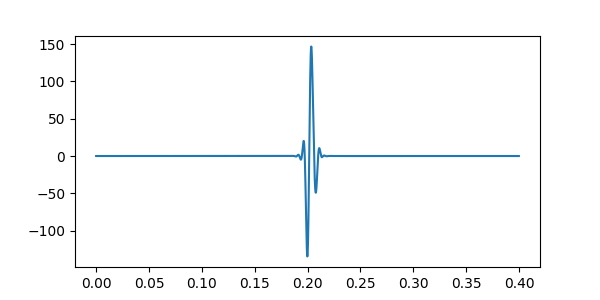

In [7]:
plt.close('all')
plt.figure(figsize=(6,3))
plt.plot(inc_wave['time'],inc_wave['trace'])
plt.show()

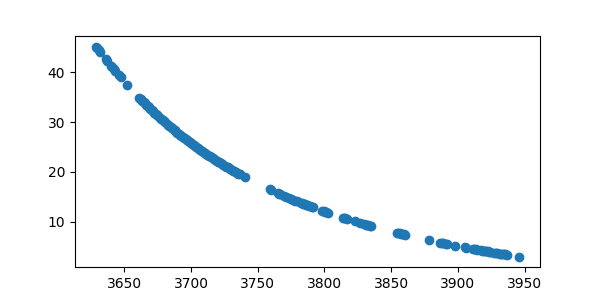

In [6]:
plt.close('all')
plt.figure(figsize=(6,3))
plt.scatter(daxis,all_angles)
plt.show()

In [6]:
# Forward modeling for multiple incident angles
#**********************************************

#define incident angles every 1 degree
init_angle=45
end_angle=18
step_angle=1
angles=np.arange(init_angle,end_angle,-step_angle)

#Choose incident angles from the reflected data
theta_i = ref_data["theta_i_deg"]
idx_test = np.abs(angles[:, None] - theta_i).argmin(axis=1)
idx_test, keep = np.unique(idx_test, return_index=True)
angles_matched = angles[keep]
theta_i_test = theta_i[idx_test]

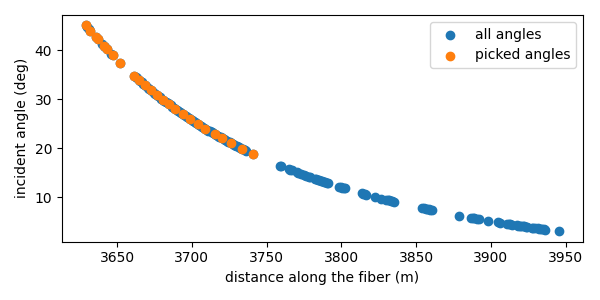

In [119]:
plt.close('all')
plt.figure(figsize=(6,3))
plt.scatter(daxis,all_angles, label='all angles')

plt.scatter(daxis[idx_test],theta_i_test, label='picked angles')
plt.xlabel('distance along the fiber (m)')
plt.ylabel('incident angle (deg)')
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Creating the true data
#******************************

#Scalar multiplying the source wavelet is always 1 for the synthetic data
s =1
#Simulated data RT waves (R_wave_batch_v2: Gd-deconvolution implicit,
#consistent with inc_wave being the raw direct trace -- see cell 3)
R_batch= DASmi.R_wave_batch_v2(
    ref_data, inc_wave, idx_test, s, vp, vs, rho, cn_true, ct_true,
    Gd=gd['Gd'], eps=eps, wave="SS",
)



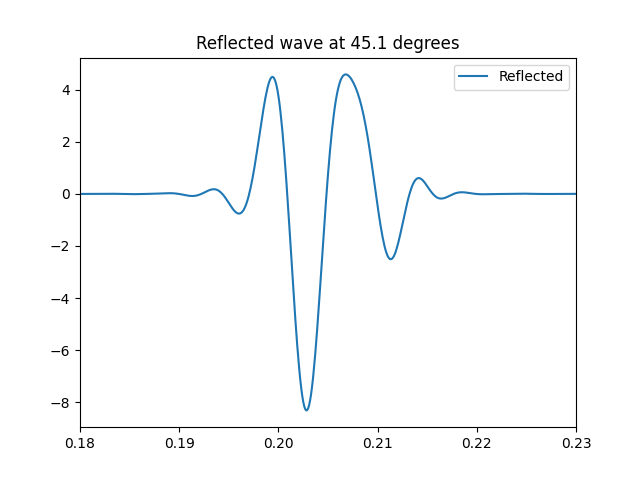

In [121]:
idx=0
angle=ref_data['theta_i_deg'][idx]
plt.close("all")

plt.plot(R_batch['time'],R_batch['Er_time'][idx],label='Reflected')
plt.title(f"Reflected wave at {angle:.1f} degrees")
plt.xlim(0.18,0.23)
plt.legend()
plt.show()

In [9]:
#inversion: fit R waves using source wavelet

#Estimating the Rwaves using a scaled source wavelet for the forward modeling
nsearch=(50,50)
search_space=[(1e-14,1e-8),(1e-14,1e-8)]

#test1: non-scaled source wavelet (scalar applied to synthetic data)
scalar1 =1

Test 1: scalar =1

In [8]:
# estimates the scalar as part of the inversion solution

gsR_time1 =DASmi.cnct_search_Rtime_Gd (
    R_batch, ref_data, inc_wave, scalar1,
    vp, vs, rho,
    Gd=gd['Gd'], eps=eps,
    search_space=search_space,
    nsearch=nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

In [10]:
#estimates the scalar as energy ratio

gsR_time1_V2 = DASmi.cnct_search_RtimeV2_Gd(
    R_batch, ref_data, inc_wave, scalar1,
    vp, vs, rho,
    Gd=gd['Gd'], eps=eps,
    search_space=search_space,
    nsearch=nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

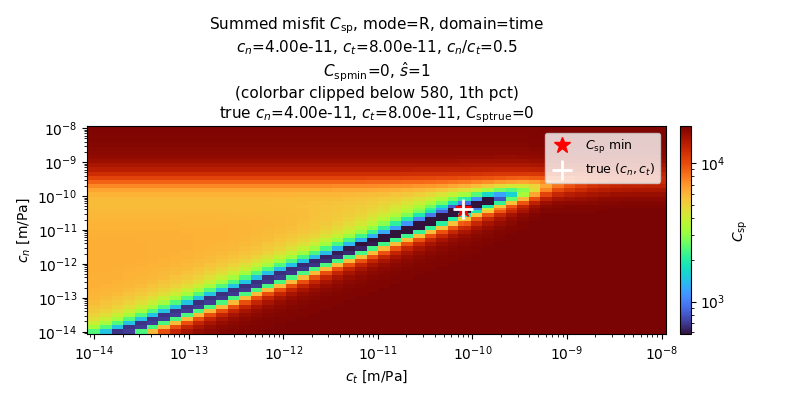

(<Figure size 800x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp}}$$_{\\mathrm{min}}$=0, $\\hat{s}$=1\n(colorbar clipped below 580, 1th pct)\ntrue $c_n$=4.00e-11, $c_t$=8.00e-11, $C_{\\mathrm{sp}}$$_{\\mathrm{true}}$=0'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [15]:
DASplt.plot_cost_sum(gsR_time1, figsize=(8, 4))

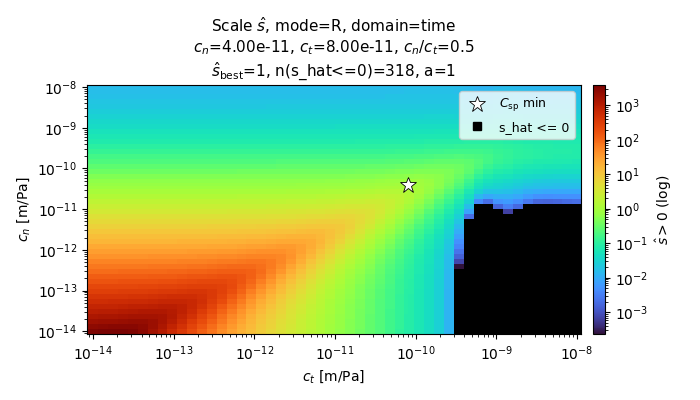

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=1, n(s_hat<=0)=318, a=1'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [16]:
DASplt.plot_s_hat(gsR_time1, figsize=(7, 4))

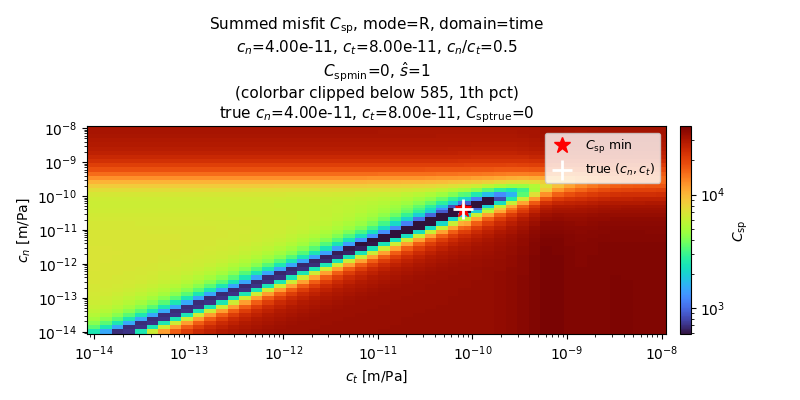

(<Figure size 800x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp}}$$_{\\mathrm{min}}$=0, $\\hat{s}$=1\n(colorbar clipped below 585, 1th pct)\ntrue $c_n$=4.00e-11, $c_t$=8.00e-11, $C_{\\mathrm{sp}}$$_{\\mathrm{true}}$=0'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [13]:
DASplt.plot_cost_sum(gsR_time1_V2, figsize=(8, 4))

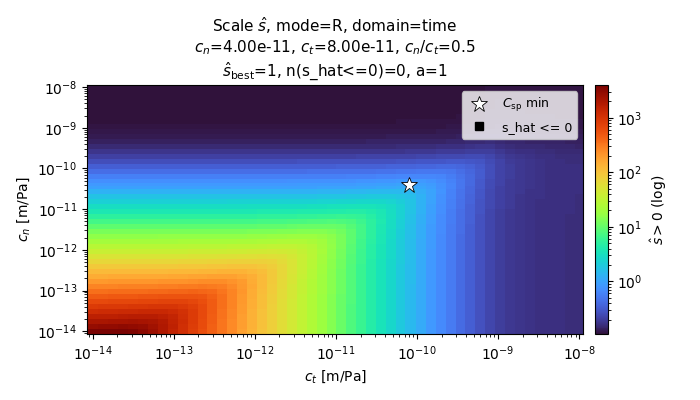

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=1, n(s_hat<=0)=0, a=1'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [14]:
DASplt.plot_s_hat(gsR_time1_V2, figsize=(7, 4))

In [ ]:
#extracting s_hat 
cnct_list=[(1e-11,1e-10),(1e-10,1e-10),(1e-9,1e-10),(8.0e-9,1e-10)]
s_list=DASmi.s_hat_at_cnct_list(gsR_time1, cnct_list)

n=0
idx=idx_test[n]
#a=scalar1: must match the scalar used by the search that produced s_list
#(gsR_time1, searched with a=scalar1)
synth_V2=DASmi.R_synth_Gd(s_list, ref_data, inc_wave, idx,
    vp, vs, rho, Gd=gd['Gd'], eps=eps, a=scalar1, wave="SS",)

fig, ax=DASplt.plot_R_synth(synth_V2, R_batch)
ax.set_xlim(0.18,0.225)


In [ ]:
gsR_omega1 = DASmi.cnct_search_Romega_Gd(
    R_batch, ref_data, inc_wave, scalar1,
    vp, vs, rho,
    Gd=gd['Gd'], eps=eps,
    search_space=search_space,
    nsearch=nsearch,
    wave="SS",
)

In [14]:
#Test1:cnct ratio
search_space11=[(0.01,10.0),(1e-14,1e-8)]
nsearch11=(50,50)


gsR_time11 = DASmi.cnct_search_Rtime_ratio_Gd(
    R_batch, ref_data, inc_wave, scalar1,
    vp, vs, rho,
    Gd=gd['Gd'], eps=eps,
    search_space=search_space11,
    nsearch=nsearch11,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

In [ ]:
n=0
idx=idx_test[n]
ratio_ct_list=[(0.5,1e-12),(0.5,1e-11),(0.5,1e-10)]
s_ratio_list=DASmi.s_hat_at_ratio_ct_list(gsR_time11, ratio_ct_list)

#a=scalar1: must match the scalar used by the search that produced
#s_ratio_list (gsR_time11, searched with a=scalar1)
synth_ratio = DASmi.R_synth_Gd(
    s_ratio_list, ref_data, inc_wave, idx,
    vp, vs, rho, Gd=gd['Gd'], eps=eps, a=scalar1, wave="SS",
)

fig, ax=DASplt.plot_R_synth(synth_ratio, R_batch)
ax.set_xlim(0.19,0.22)

In [ ]:
DASplt.plot_cost_sum(gsR_time11, figsize=(8, 4))

In [ ]:
DASplt.plot_s_hat(gsR_time11, figsize=(7, 4))

In [ ]:
DASplt.plot_s_hat(gsR_time1, figsize=(7, 4))

Scalar=2.5

In [10]:
#test2: changin the scalar applied to the source wavelet for the forward modelinng
scalar2 =2.5
gsR_time2 = DASmi.cnct_search_Rtime_Gd(
    R_batch, ref_data, inc_wave, scalar2,
    vp, vs, rho,
    Gd=gd['Gd'], eps=eps,
    search_space=search_space,
    nsearch=nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

In [18]:

gsR_time22 = DASmi.cnct_search_Rtime_ratio_Gd(
    R_batch, ref_data, inc_wave, scalar2,
    vp, vs, rho,
    Gd=gd['Gd'], eps=eps,
    search_space=search_space11,
    nsearch=nsearch11,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

In [12]:
gsR_time2_V2 = DASmi.cnct_search_RtimeV2_Gd(
    R_batch, ref_data, inc_wave, scalar2,
    vp, vs, rho,
    Gd=gd['Gd'], eps=eps,
    search_space=search_space,
    nsearch=nsearch,
    wave="SS",
)

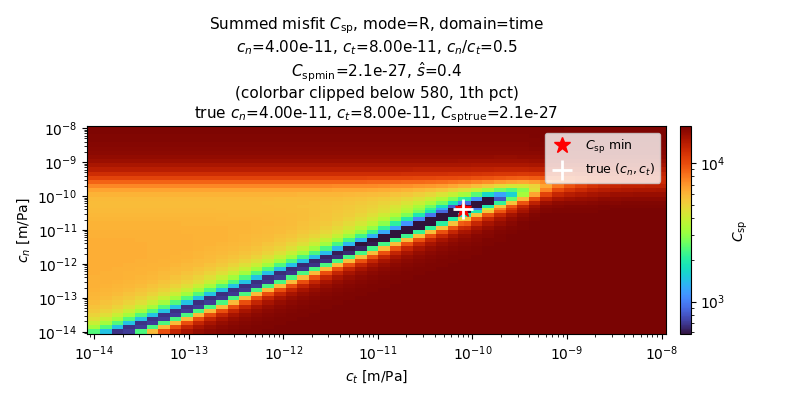

(<Figure size 800x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp}}$$_{\\mathrm{min}}$=2.1e-27, $\\hat{s}$=0.4\n(colorbar clipped below 580, 1th pct)\ntrue $c_n$=4.00e-11, $c_t$=8.00e-11, $C_{\\mathrm{sp}}$$_{\\mathrm{true}}$=2.1e-27'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [11]:
DASplt.plot_cost_sum(gsR_time2, figsize=(8, 4))

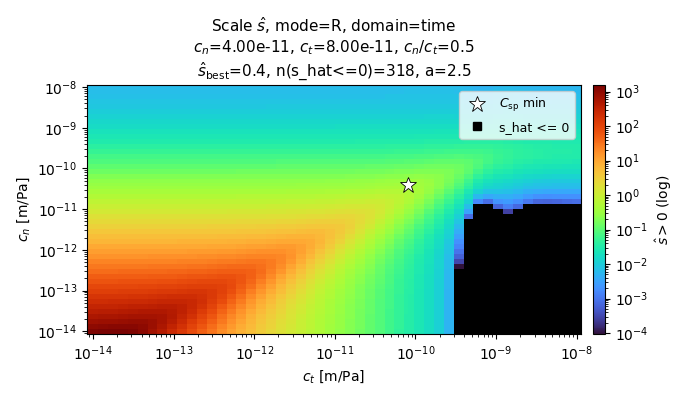

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=0.4, n(s_hat<=0)=318, a=2.5'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [13]:
DASplt.plot_s_hat(gsR_time2, figsize=(7, 4))

In [ ]:
DASplt.plot_cost_sum(gsR_time22, figsize=(8, 4))

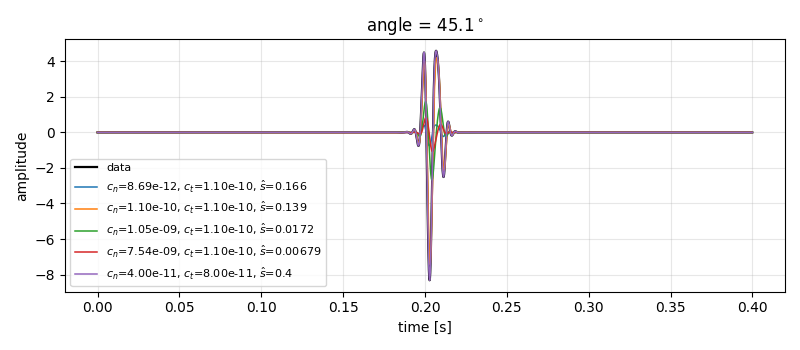

(0.18, 0.225)

In [12]:
#waveforms from cnct inversion
cnct_list=[(1e-11,1e-10),(1e-10,1e-10),(1e-9,1e-10),(8.0e-9,1e-10), (cn_true, ct_true)]
s_list=DASmi.s_hat_at_cnct_list(gsR_time2, cnct_list)

n=0
idx=idx_test[n]
#a=scalar2: must match the scalar used by the search that produced s_list
#(gsR_time2, searched with a=scalar2)
synth_V2=DASmi.R_synth_Gd(s_list, ref_data, inc_wave, idx,
    vp, vs, rho, Gd=gd['Gd'], eps=eps, a=scalar2, wave="SS",)

fig, ax=DASplt.plot_R_synth(synth_V2, R_batch)
ax.set_xlim(0.18,0.225)

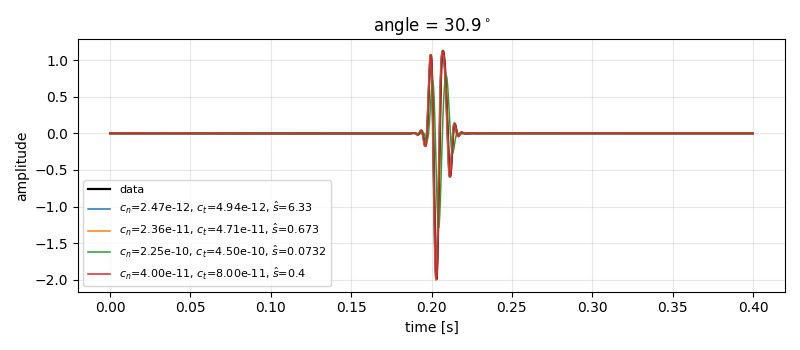

(0.19, 0.22)

In [24]:
#waveforms from cnct RATIO inversion
n=12
idx=idx_test[n]
ratio_ct_list=[(0.5,5e-12),(0.5,5e-11),(0.5,5e-10), (0.5,ct_true)]
s_ratio_list=DASmi.s_hat_at_ratio_ct_list(gsR_time22, ratio_ct_list)

#a=scalar2: must match the scalar used by the search that produced
#s_ratio_list (gsR_time22, searched with a=scalar2)
synth_ratio = DASmi.R_synth_Gd(
    s_ratio_list, ref_data, inc_wave, idx,
    vp, vs, rho, Gd=gd['Gd'], eps=eps, a=scalar2, wave="SS",
)

fig, ax=DASplt.plot_R_synth(synth_ratio, R_batch)
ax.set_xlim(0.19,0.22)

Test 3: CC before cost function

In [39]:
scalar2 =2.5
gsR_time3 = DASmi.cnct_search_Rtime_Gd_cc(
    R_batch, ref_data, inc_wave, scalar2,
    vp, vs, rho,
    Gd=gd['Gd'], eps=eps,
    search_space=search_space,
    nsearch=nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

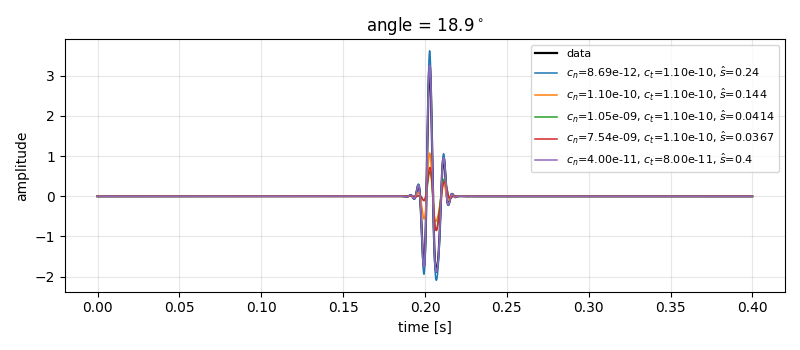

(0.18, 0.225)

In [40]:
cnct_list=[(1e-11,1e-10),(1e-10,1e-10),(1e-9,1e-10),(8.0e-9,1e-10), (cn_true, ct_true)]
s_list = DASmi.s_hat_at_cnct_list(gsR_time3, cnct_list)          # global, unchanged

n=-1
idx=idx_test[n]
lag_arr = DASmi.lag_at_list(gsR_time3, s_list['i'], s_list['j'], idx)  # per-trace

synth_V2 = DASmi.R_synth_Gd_cc(s_list, lag_arr, ref_data, inc_wave, idx,
    vp, vs, rho, Gd=gd['Gd'], eps=eps, a=scalar2, wave="SS")
fig, ax = DASplt.plot_R_synth(synth_V2, R_batch)
ax.set_xlim(0.18, 0.225)


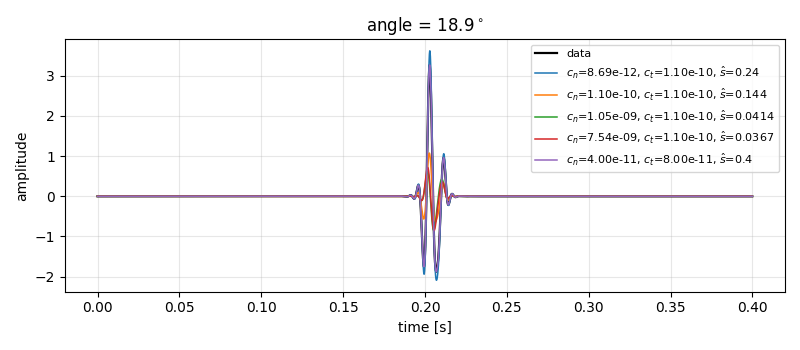

(0.18, 0.225)

In [41]:
#waveforms from cnct inversion (not cc-shifted)
cnct_list=[(1e-11,1e-10),(1e-10,1e-10),(1e-9,1e-10),(8.0e-9,1e-10), (cn_true, ct_true)]
s_list=DASmi.s_hat_at_cnct_list(gsR_time3, cnct_list)

n=-1
idx=idx_test[n]
#a=scalar2: must match the scalar used by the search that produced s_list
#(gsR_time2, searched with a=scalar2)
synth_V2=DASmi.R_synth_Gd(s_list, ref_data, inc_wave, idx,
    vp, vs, rho, Gd=gd['Gd'], eps=eps, a=scalar2, wave="SS",)

fig, ax=DASplt.plot_R_synth(synth_V2, R_batch)
ax.set_xlim(0.18,0.225)

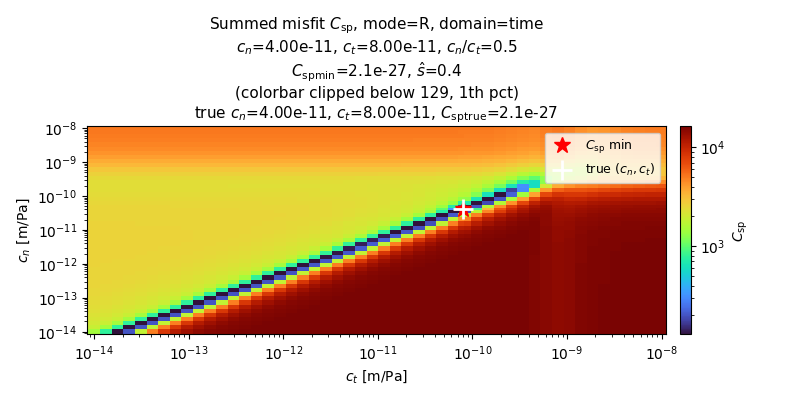

(<Figure size 800x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp}}$$_{\\mathrm{min}}$=2.1e-27, $\\hat{s}$=0.4\n(colorbar clipped below 129, 1th pct)\ntrue $c_n$=4.00e-11, $c_t$=8.00e-11, $C_{\\mathrm{sp}}$$_{\\mathrm{true}}$=2.1e-27'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [30]:
DASplt.plot_cost_sum(gsR_time3, figsize=(8, 4))

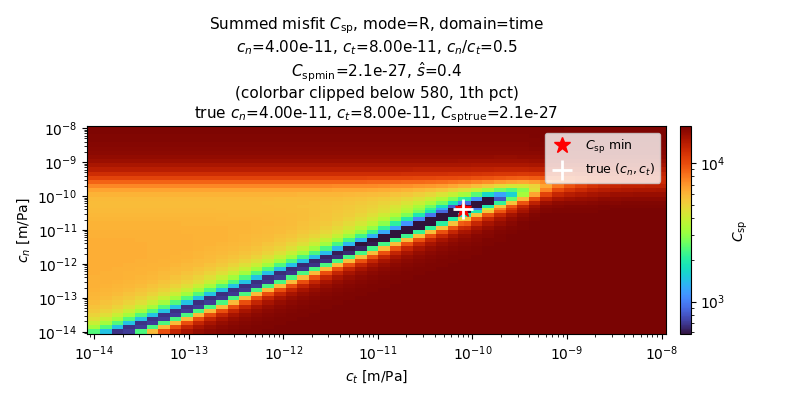

(<Figure size 800x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp}}$$_{\\mathrm{min}}$=2.1e-27, $\\hat{s}$=0.4\n(colorbar clipped below 580, 1th pct)\ntrue $c_n$=4.00e-11, $c_t$=8.00e-11, $C_{\\mathrm{sp}}$$_{\\mathrm{true}}$=2.1e-27'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [38]:
DASplt.plot_cost_sum(gsR_time2, figsize=(8, 4))

In [1]:
DASplt.plot_s_hat(gsR_time2, figsize=(7, 4))

NameError: name 'DASplt' is not defined

In [31]:
gsR_time33 = DASmi.cnct_search_Rtime_ratio_Gd_cc(
    R_batch, ref_data, inc_wave, scalar2,
    vp, vs, rho,
    Gd=gd['Gd'], eps=eps,
    search_space=search_space11,
    nsearch=nsearch11,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

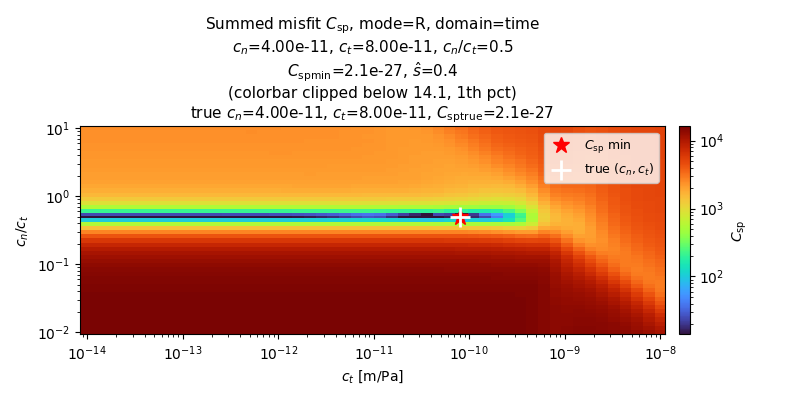

(<Figure size 800x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp}}$$_{\\mathrm{min}}$=2.1e-27, $\\hat{s}$=0.4\n(colorbar clipped below 14.1, 1th pct)\ntrue $c_n$=4.00e-11, $c_t$=8.00e-11, $C_{\\mathrm{sp}}$$_{\\mathrm{true}}$=2.1e-27'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n / c_t$'>)

In [32]:
DASplt.plot_cost_sum(gsR_time33, figsize=(8, 4))

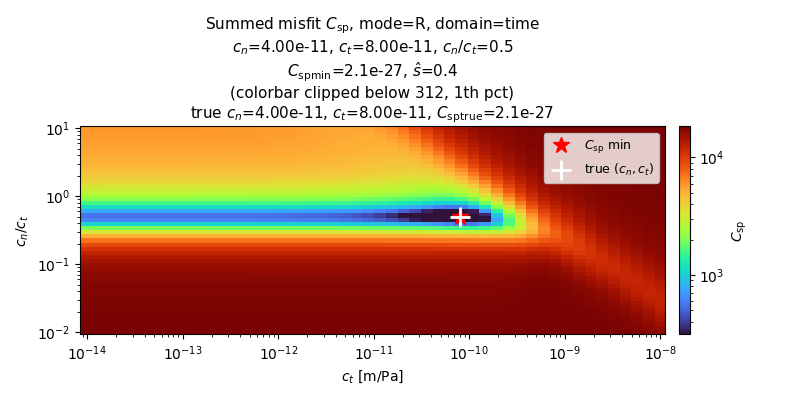

(<Figure size 800x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=4.00e-11, $c_t$=8.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp}}$$_{\\mathrm{min}}$=2.1e-27, $\\hat{s}$=0.4\n(colorbar clipped below 312, 1th pct)\ntrue $c_n$=4.00e-11, $c_t$=8.00e-11, $C_{\\mathrm{sp}}$$_{\\mathrm{true}}$=2.1e-27'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n / c_t$'>)

In [47]:
DASplt.plot_cost_sum(gsR_time22, figsize=(8, 4))

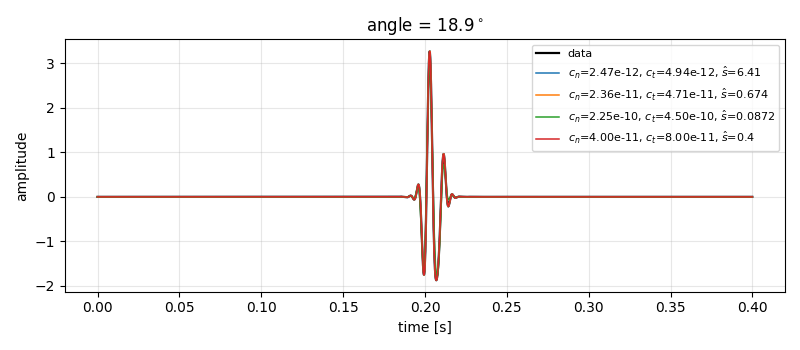

(0.19, 0.22)

In [49]:
#waveforms from cnct RATIO inversion
n=-1
idx=idx_test[n]
ratio_ct_list=[(0.5,5e-12),(0.5,5e-11),(0.5,5e-10), (0.5,ct_true)]
s_ratio_list=DASmi.s_hat_at_ratio_ct_list(gsR_time33, ratio_ct_list)

lag_arr = DASmi.lag_at_list(gsR_time33, s_ratio_list['i'], s_ratio_list['j'], idx)  # per-trace

#a=scalar2: must match the scalar used by the search that produced
#s_ratio_list (gsR_time33, searched with a=scalar2)
synth_V2 = DASmi.R_synth_Gd_cc(s_ratio_list, lag_arr, ref_data, inc_wave, idx,
    vp, vs, rho, Gd=gd['Gd'], eps=eps, a=scalar2, wave="SS")

fig, ax=DASplt.plot_R_synth(synth_V2, R_batch)
ax.set_xlim(0.19,0.22)


OLD CODE

In [46]:
#Inversion: Fit RT waves using source wavelet
#***********
# Estimate fracture compliance by grid search

#nsearch=(40,20)
#search_space=[(1e-14,1e-8),(0.01,3.0)]
nsearch=(50,50)
search_space=[(1e-14,1e-10),(1e-14,1e-10)]

#Frequency domain
modeR="R"
#gsR=DASmi.cnct_search_RTomega(
    #RT_batch, scattering_data, inc_wave, vp, vs, rho, modeR,
    #search_space, nsearch, wave="SS")
gsR=DASmi.cnct_search_RTomegaV2(
    RT_batch, scattering_data, inc_wave, vp, vs, rho, modeR,
    search_space, nsearch, wave="SS")

modeT="T"
#gsT=DASmi.cnct_search_RTomega(
    #RT_batch, scattering_data, inc_wave, vp, vs, rho, modeT,
    #search_space, nsearch, wave="SS")
gsT=DASmi.cnct_search_RTomegaV2(
    RT_batch, scattering_data, inc_wave, vp, vs, rho, modeT,
    search_space, nsearch, wave="SS")



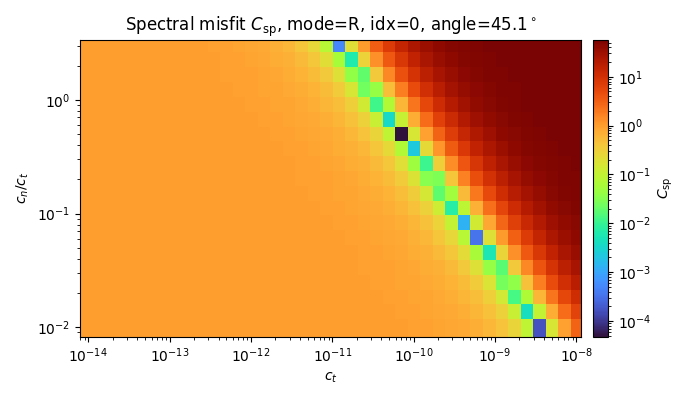

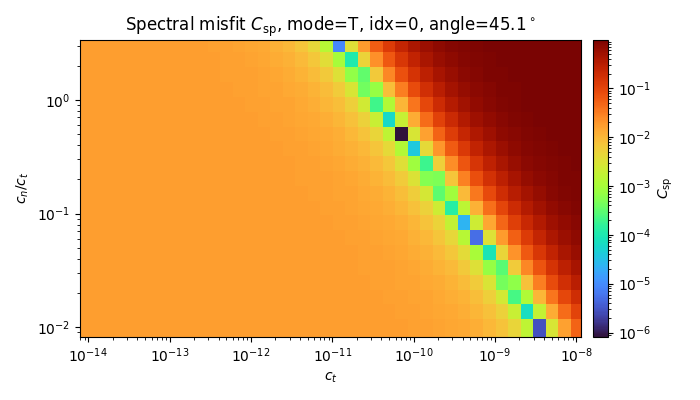

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Spectral misfit $C_{\\mathrm{sp}}$, mode=T, idx=0, angle=45.1$^\\circ$'}, xlabel='$c_t$', ylabel='$c_n / c_t$'>)

In [ ]:
idx=0
DASplt.plot_cost(gsR, RT_batch, idx)


In [58]:
#
#Forward modeling per angle
angle=10
Gt=scattering_data['Gt'][0]
Gr=scattering_data['Gr'][0]
RT_angle=DASmi.RT_wave_angle(
    Gt,
    Gr,
    angle,
    inc_wave,
    vp,
    vs,
    rho,
    cn,
    ct,
    wave="SS")

In [59]:
gsR_angle = DASmi.cnct_anglesearch_omega(
    RT_angle, Gt, Gr, inc_wave, vp, vs, rho,
    mode="R",
    search_space=[(1e-14, 1e-8), (1e-14, 1e-8)],
    nsearch=(50, 50),
    wave="SS",
)

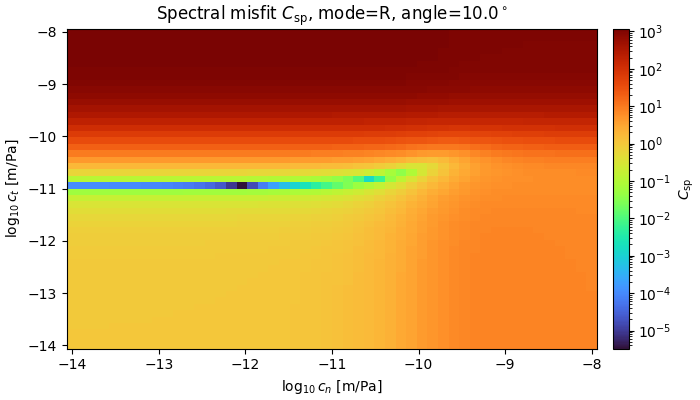

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Spectral misfit $C_{\\mathrm{sp}}$, mode=R, angle=10.0$^\\circ$'}, xlabel='$\\log_{10} c_n$ [m/Pa]', ylabel='$\\log_{10} c_t$ [m/Pa]'>)

In [60]:
DASplt.plot_cost_angle(gsR_angle)